# ANA-066 — Observation-aware global calibration

RUN-170 / EXP-065. Six frozen global fits, 64 new empirical confirmation cubes,
16 new synthetic landscape seeds. Calibration uses measured marginal fitness,
near-floor mass and average local SD. WHT and diminishing returns are withheld.

This notebook audits saved data and regenerates every figure and summary table.
Assertions check provenance and numerical identities, never scientific success
gates. Repeated observation draws are not independent landscape replicates.
See `../analysis.md` for interpretation and `../README.md` for restoration.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
NOTEBOOKS=ROOT/'analyses/2026-10-08_ANA-066_run-170-observation-aware-global-calibration/notebooks'
if not NOTEBOOKS.exists():
    ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AIM.md').exists())
    NOTEBOOKS=ROOT/'analyses/2026-10-08_ANA-066_run-170-observation-aware-global-calibration/notebooks'
sys.path.insert(0,str(NOTEBOOKS))
import analysis_tools as a
from IPython.display import display, Image
import matplotlib.pyplot as plt
data=a.audit_and_load()
data['audit']

{'output_hashes': 103,
 'remote_hashes': 212,
 'source_hashes': 7,
 'empirical_genotypes': 2048,
 'excluded_genotypes': 3712,
 'independent_statistic_rows': 114432,
 'replicate_pair_cubes': 38144,
 'replayed_observations': 1179648,
 'fits_recomputed': 6,
 'checks': 'Numerical/provenance identities, not scientific gates.'}

## Uncertainty and estimands

Percentile intervals use 1,000 resamples of empirical cubes or synthetic landscape
seeds, keeping each seed's cubes and observation draws together. They describe
conditional sampling variation: fitted parameters, donor calibration and the
assay remain fixed. Ordinary replicate-average results are primary; cross and
stop-adjusted estimates and availability are retained in the tables. Equal-cube
fractions and ratios of pooled powers answer different questions. Slopes average
eligible mutation slopes within cubes and then equally across available cubes;
beneficial-only slopes are a separate conditional statistic.

In [2]:
summary=a.summarize(data)
summary.shape

(624, 9)

## Calibration

The loss contains no WHT or slope statistic. Finite optimizer budgets and parameter bounds are reported; this is a parameter search, not proof of the best possible fit.

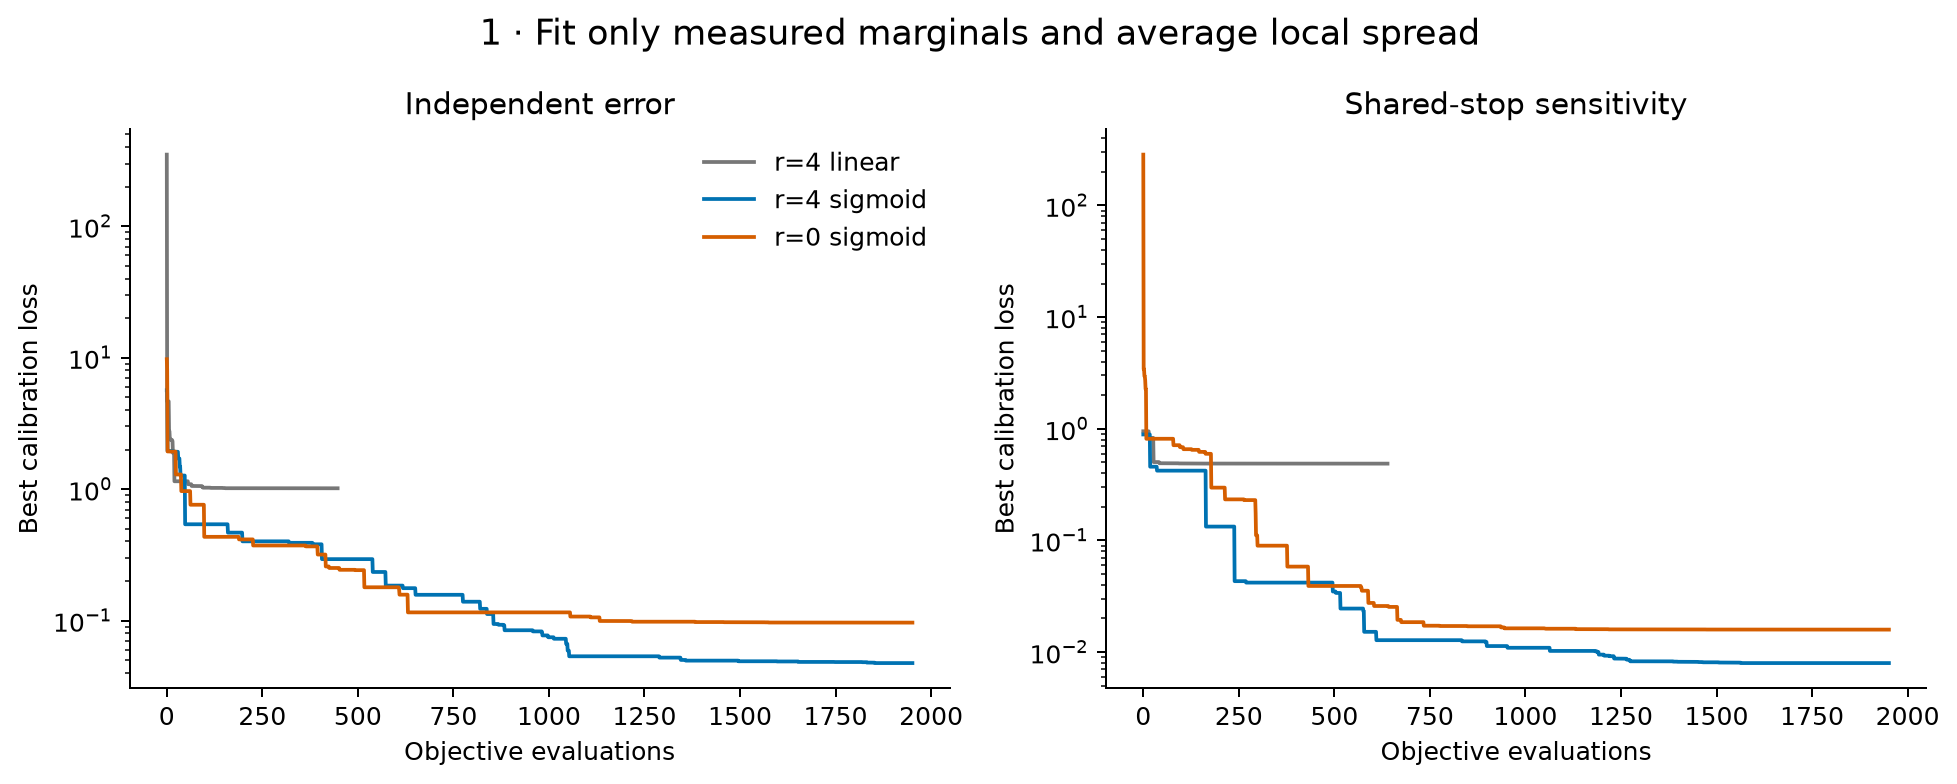

In [3]:
fig=a.figure_fit(data)
display(Image(filename=str(a.FIGURES/'01_calibration.png')))
plt.close(fig)

## Held-out marginal predictions

The marginal fitness target was fitted on calibration cubes. The full distribution of local SD was withheld. Lines pool repeated observations descriptively; uncertainty is clustered by seed in subsequent figures.

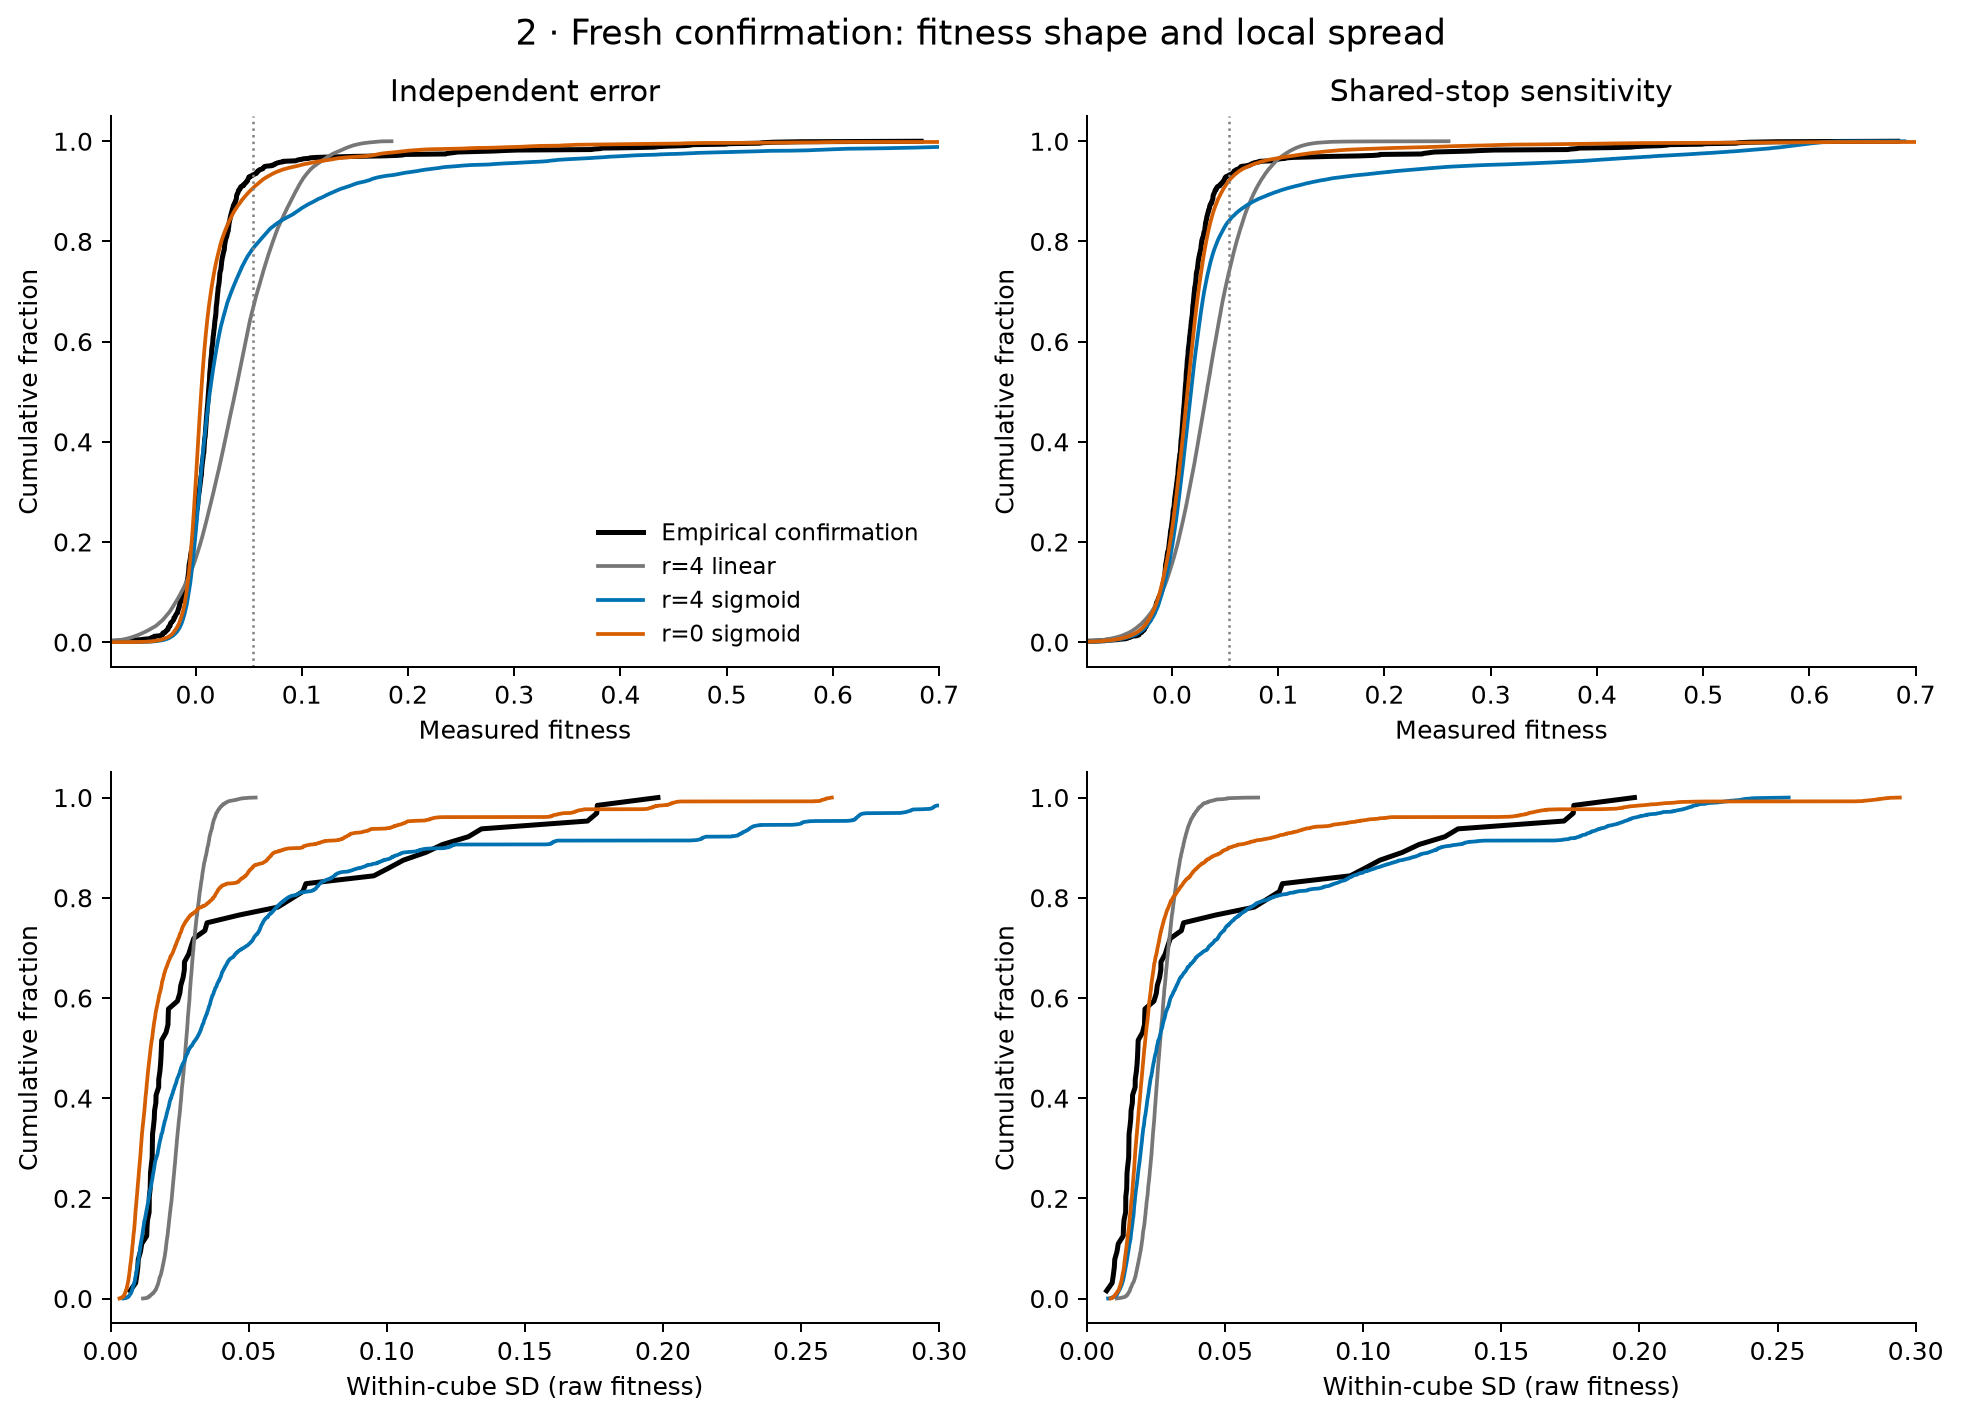

In [4]:
fig=a.figure_marginals(data)
display(Image(filename=str(a.FIGURES/'02_heldout_marginals.png')))
plt.close(fig)

## Withheld WHT

Points and 95% bootstrap intervals. Absolute powers use raw fitness squared. All nonconstant epistasis includes orders 2–4; high-order includes 3–4. No corrected negative power is clipped.

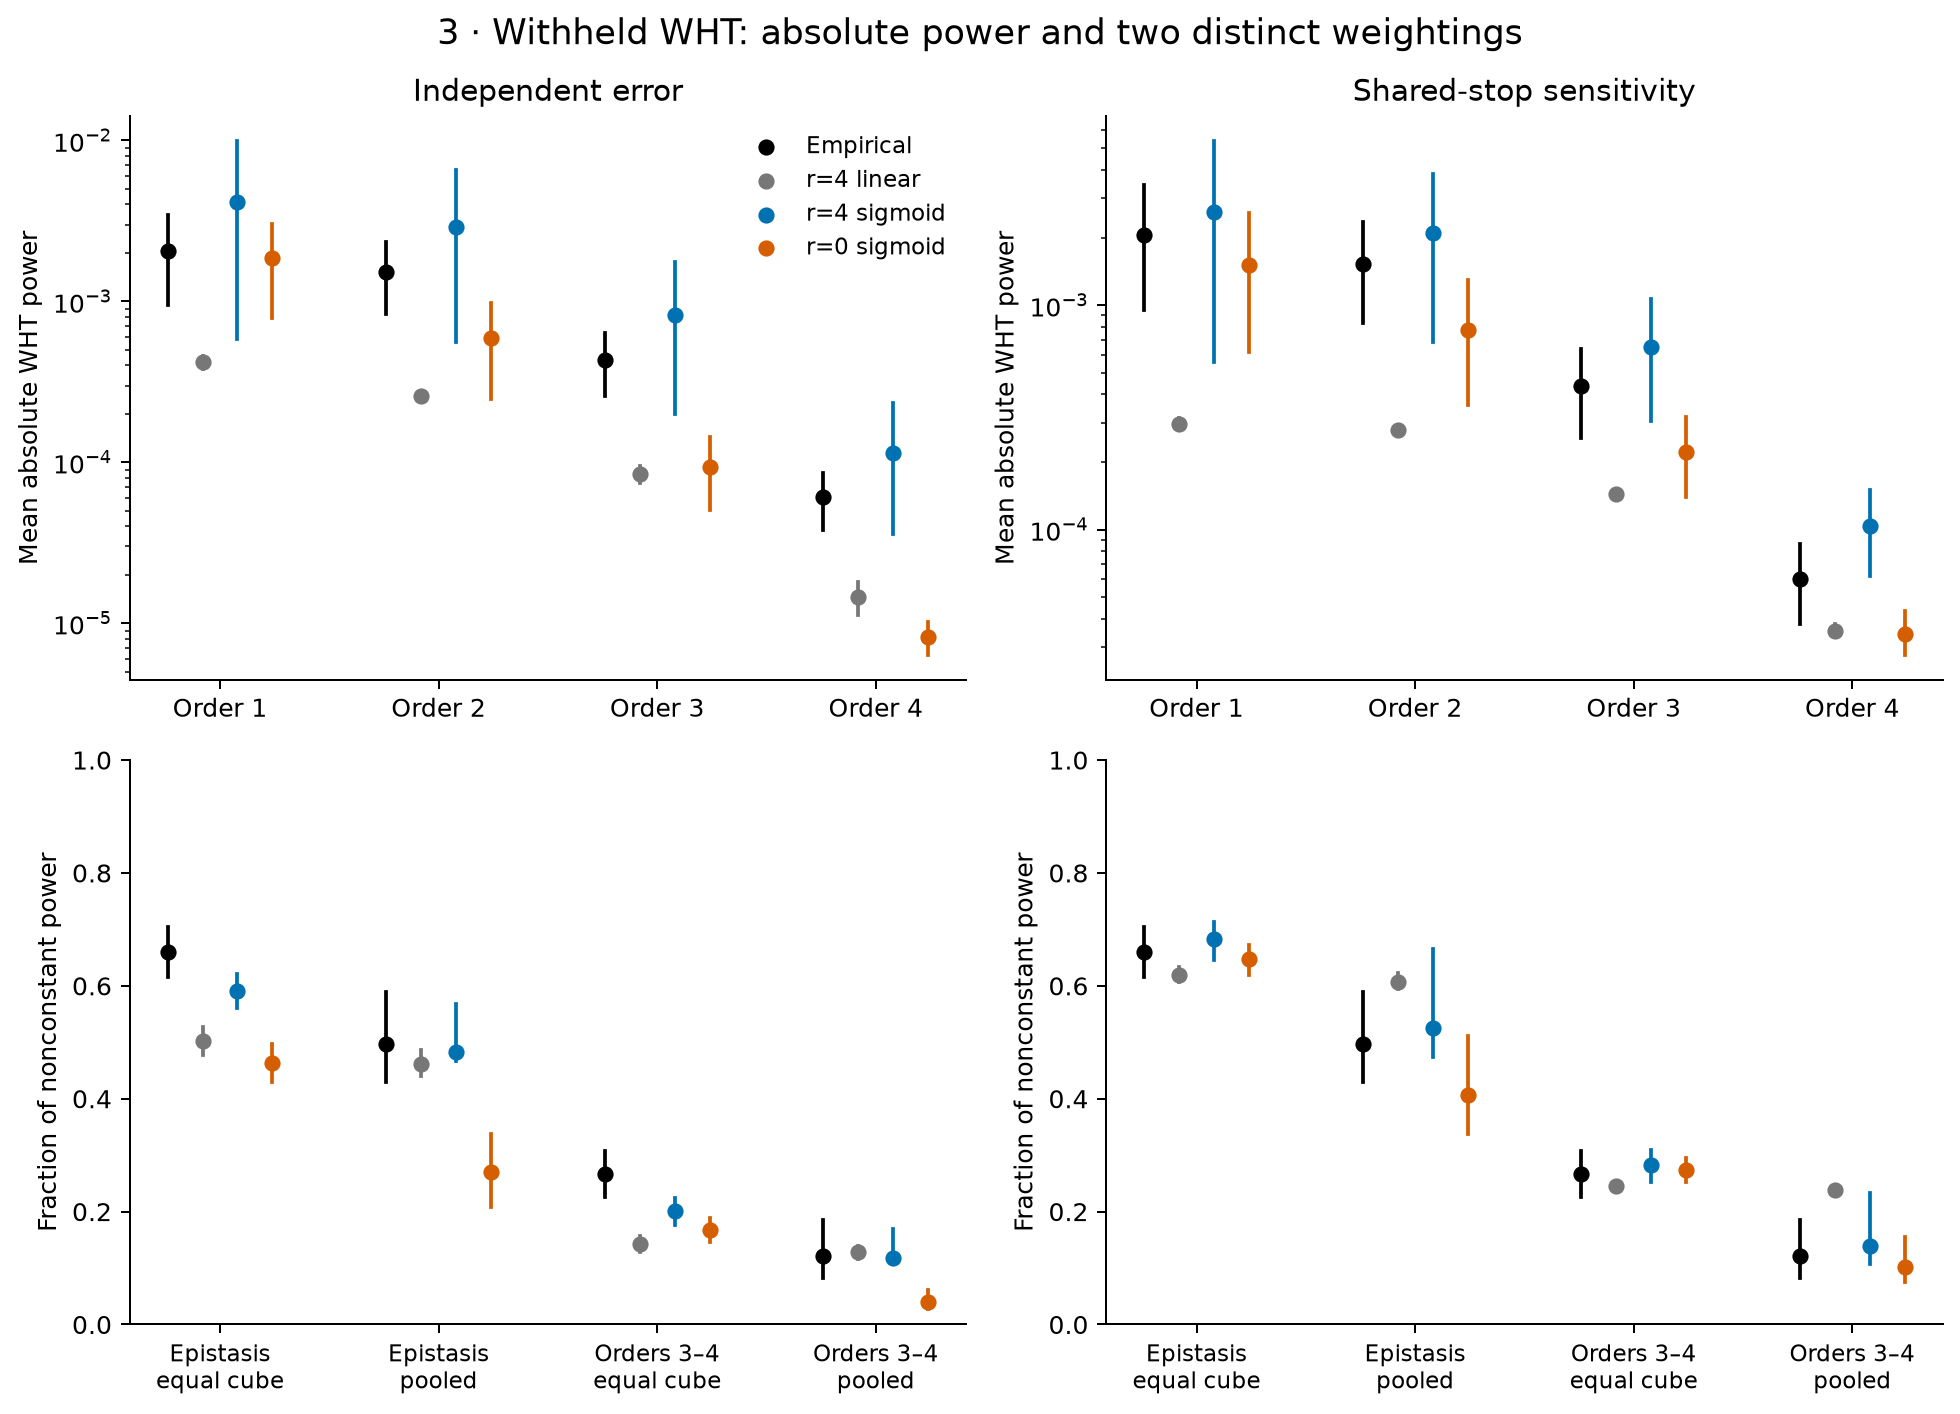

In [5]:
fig=a.figure_wht(data)
display(Image(filename=str(a.FIGURES/'03_withheld_wht.png')))
plt.close(fig)

## Withheld diminishing returns

Slopes and denominator availability are shown together. Beneficial-only selection can produce a different result from all-mutation slopes. Raw numerator/denominator arrays and mutation tables are retained.

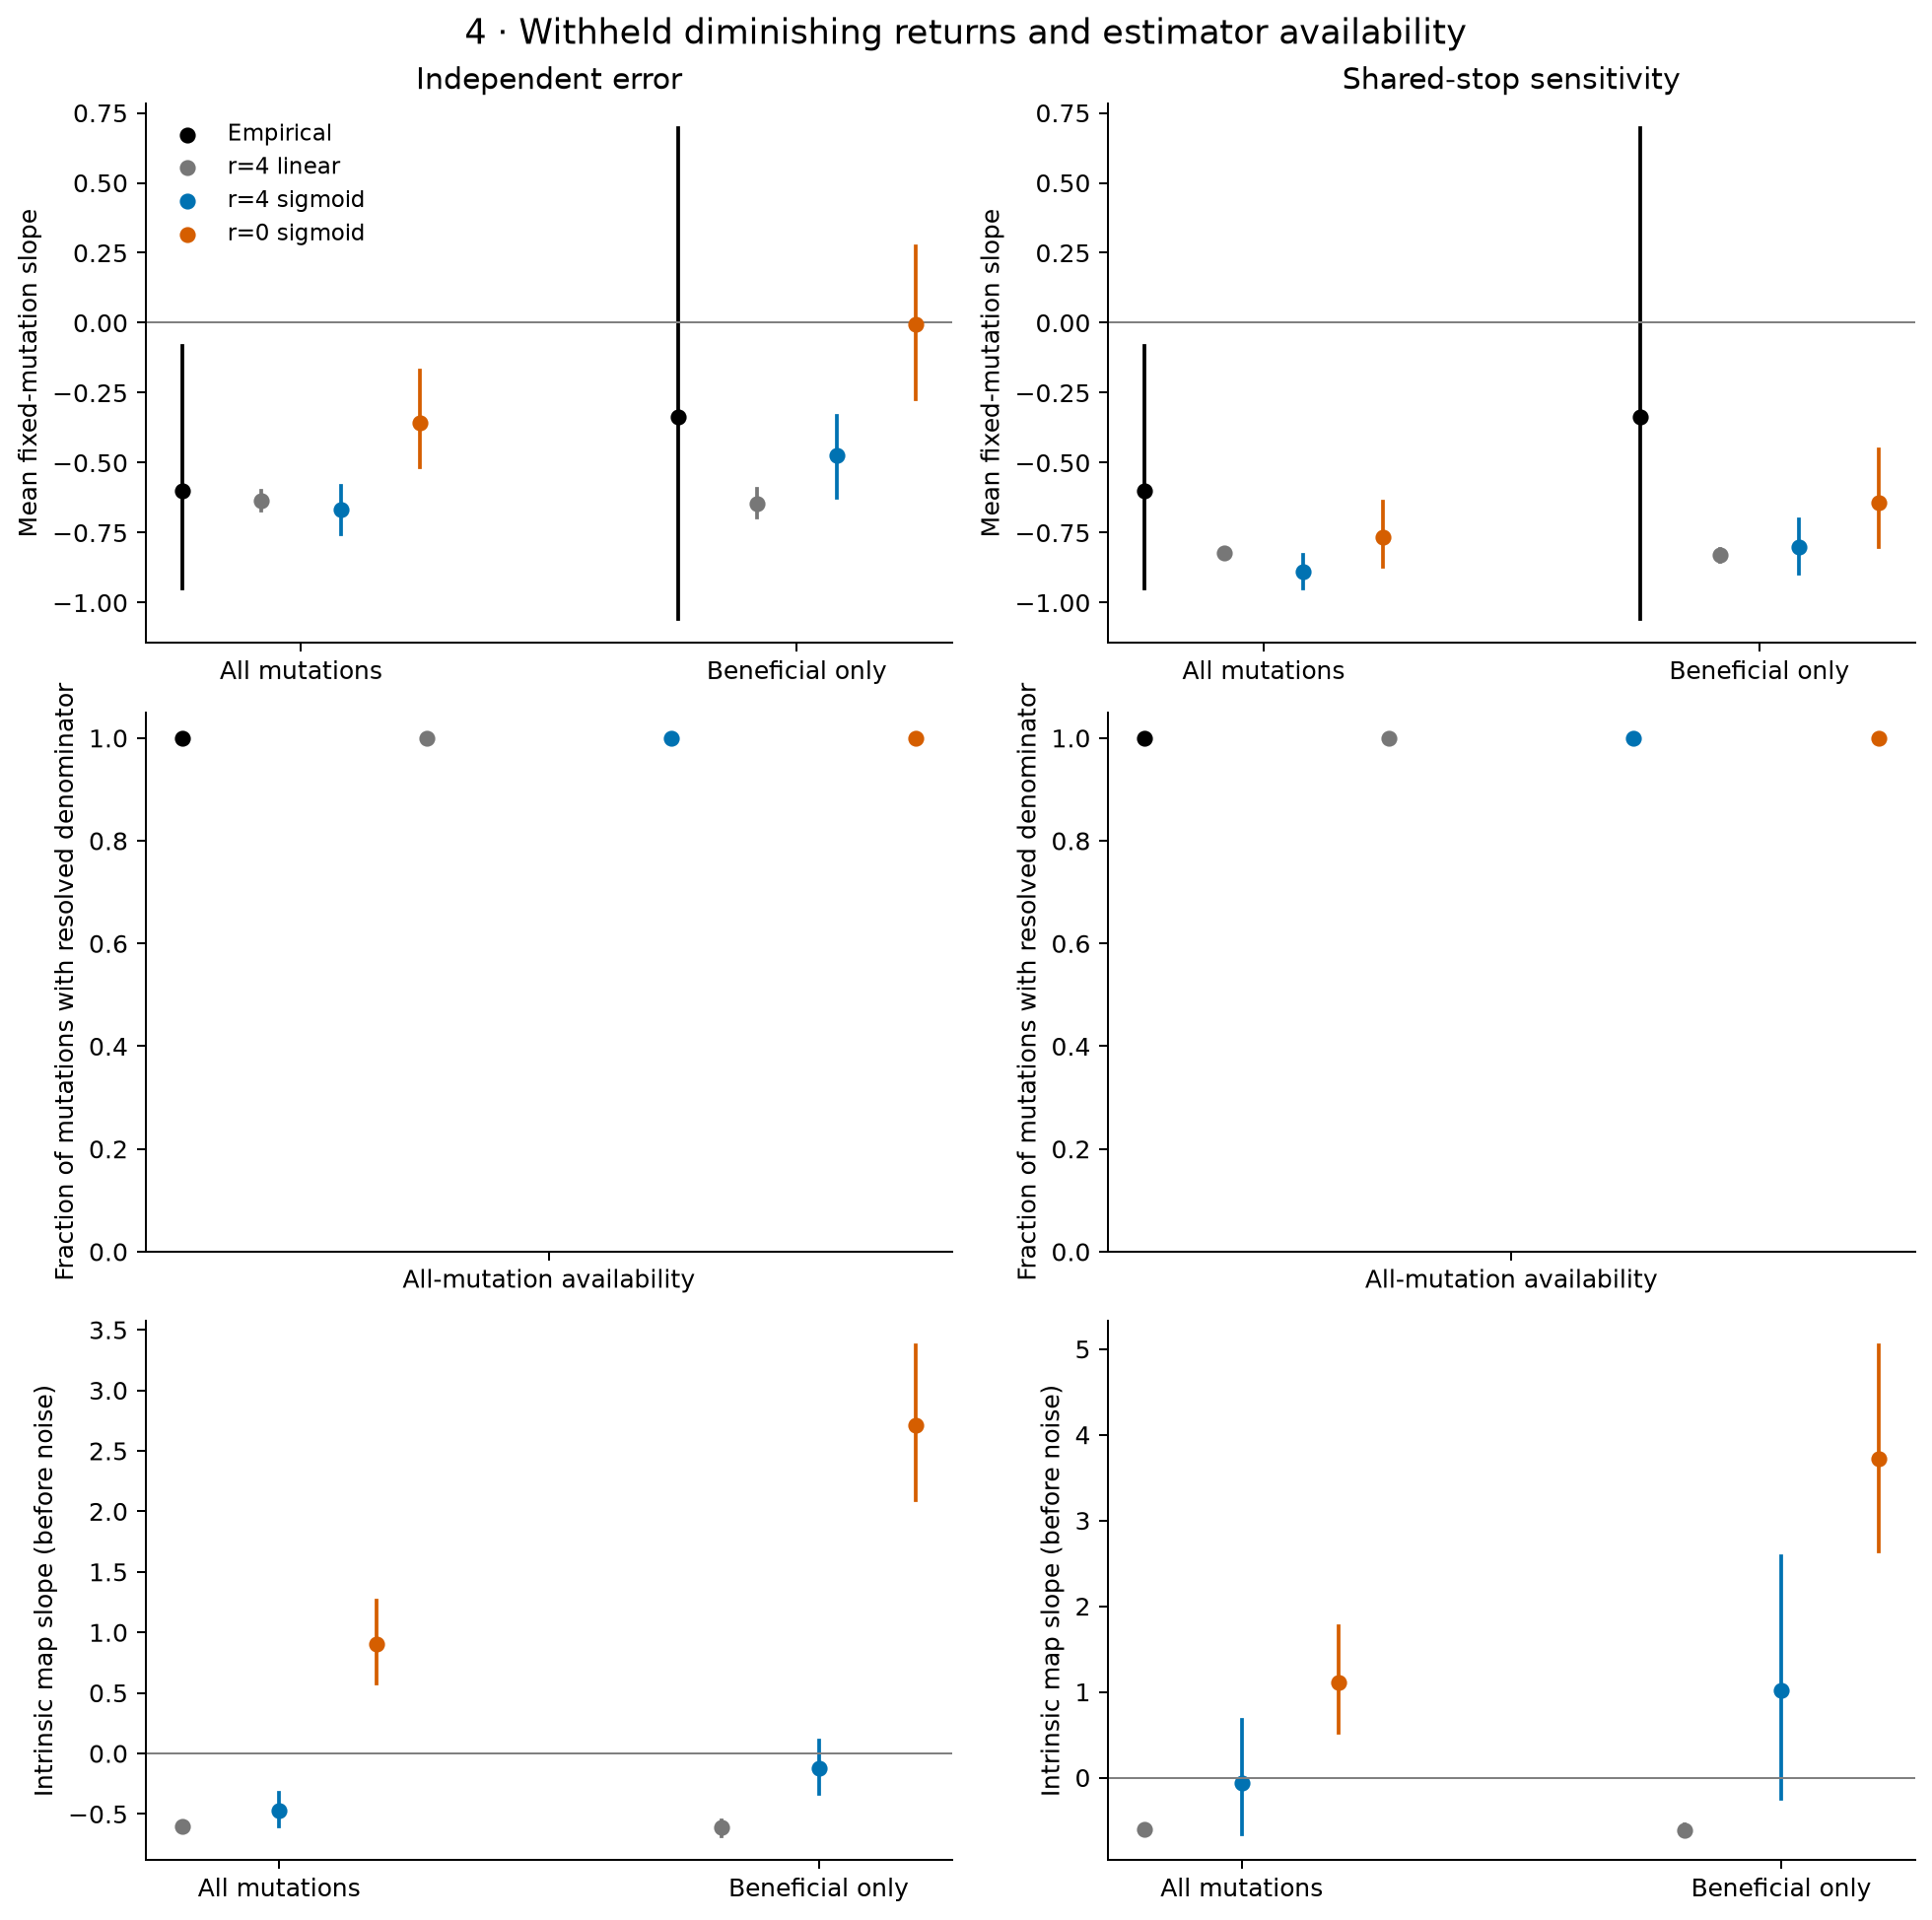

In [6]:
fig=a.figure_slopes(data)
display(Image(filename=str(a.FIGURES/'04_withheld_slopes.png')))
plt.close(fig)

## Activity and conditional structure

Activity requires both replicates above published assay cutoffs. Bottom panels average repeated synthetic observations within each cube; they diagnose where the remaining spectral differences occur.

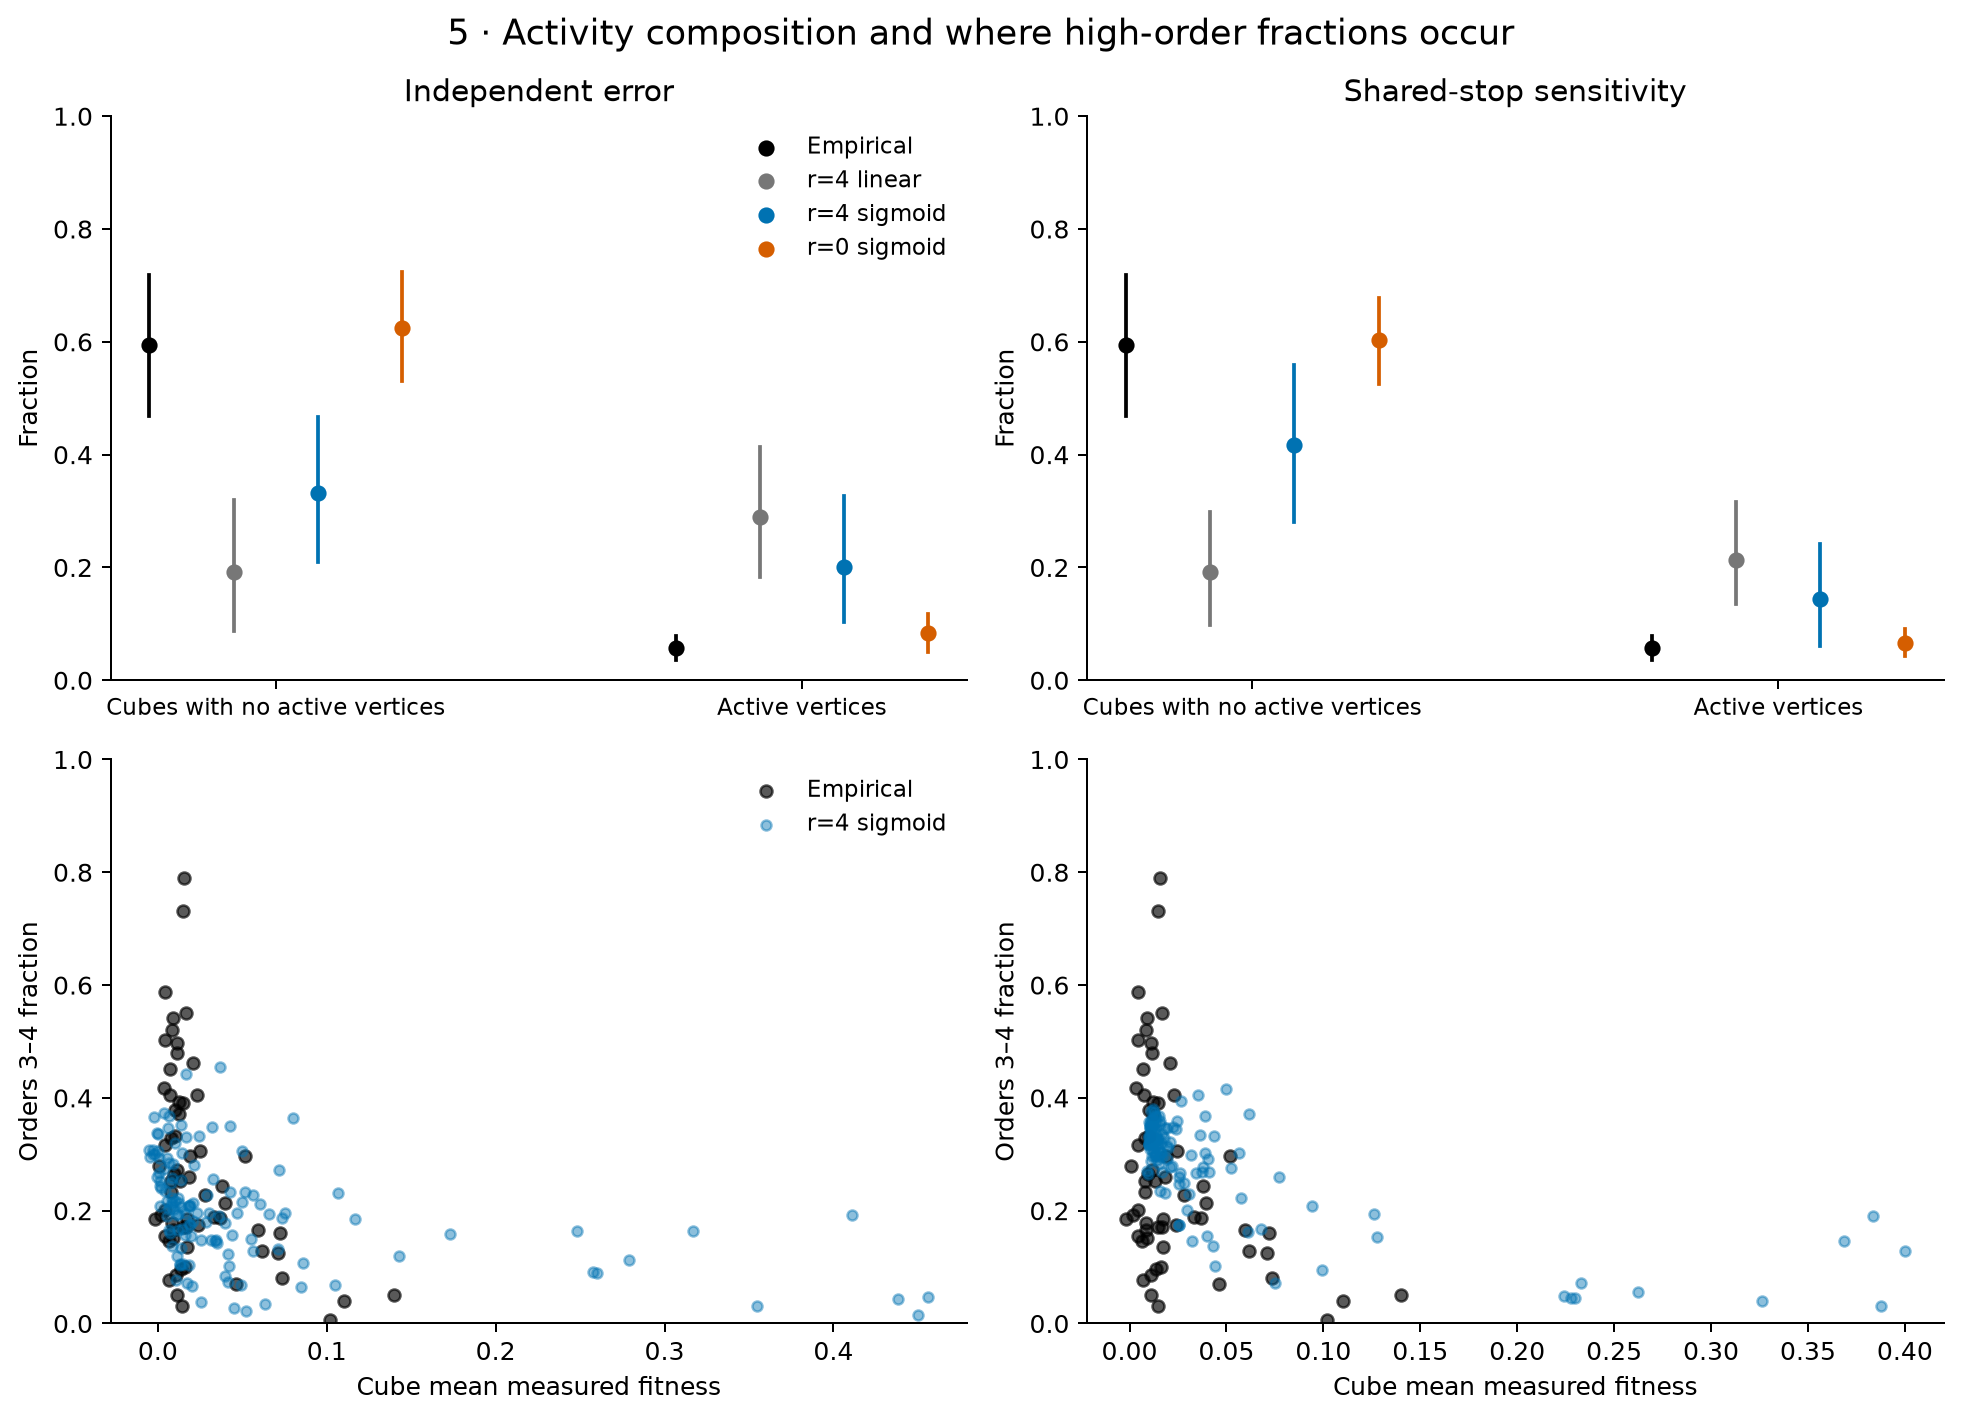

In [7]:
fig=a.figure_activity(data)
display(Image(filename=str(a.FIGURES/'05_activity_and_structure.png')))
plt.close(fig)

## Values underlying interpretation

These are descriptors, not acceptance thresholds. Portable fitted sigmoid
parameters are exported to `tables/portable_parameters.json`. Intrinsic map
summaries are included to separate latent biological structure from observational
variation. Four-site assay resemblance does not establish invariant global
statistics at all lengths.

In [8]:
primary=summary[(summary.method=='average') & ~summary.observation.str.endswith('_intrinsic')]
display(primary.pivot(index=['observation','arm'],columns='metric',values='value').round(4))

metric                              active_vertices  beneficial_count  \
observation             arm                                             
empirical               empirical            0.0576            1.8594   
independent_difference  r0_sigmoid           0.0833            1.9375   
                        r4_linear            0.2894            1.9971   
                        r4_sigmoid           0.1999            1.9695   
shared_stop_sensitivity r0_sigmoid           0.0652            1.9521   
                        r4_linear            0.2131            2.0115   
                        r4_sigmoid           0.1444            1.8792   

metric                              beneficial_slope  equal_epistasis  \
observation             arm                                             
empirical               empirical            -0.3350           0.6601   
independent_difference  r0_sigmoid           -0.0045           0.4628   
                        r4_linear            -0.6448           0.5019   
                        r4_sigmoid           -0.4742           0.5908   
shared_stop_sensitivity r0_sigmoid           -0.6429           0.6467   
                        r4_linear            -0.8298           0.6193   
                        r4_sigmoid           -0.7997           0.6831   

metric                              equal_ho  mean_fitness  mean_sd  \
observation             arm                                           
empirical               empirical     0.2673        0.0236   0.0423   
independent_difference  r0_sigmoid    0.1682        0.0202   0.0298   
                        r4_linear     0.1420        0.0389   0.0273   
                        r4_sigmoid    0.2004        0.0531   0.0547   
shared_stop_sensitivity r0_sigmoid    0.2742        0.0220   0.0321   
                        r4_linear     0.2449        0.0334   0.0268   
                        r4_sigmoid    0.2828        0.0468   0.0500   

metric                              no_active  pooled_epistasis  pooled_ho  \
observation             arm                                                  
empirical               empirical      0.5938            0.4963     0.1213   
independent_difference  r0_sigmoid     0.6248            0.2706     0.0397   
                        r4_linear      0.1926            0.4619     0.1276   
                        r4_sigmoid     0.3315            0.4834     0.1176   
shared_stop_sensitivity r0_sigmoid     0.6025            0.4058     0.1012   
                        r4_linear      0.1919            0.6071     0.2384   
                        r4_sigmoid     0.4175            0.5248     0.1388   

metric                              power_1  power_2  power_3  power_4  \
observation             arm                                              
empirical               empirical    0.0021   0.0015   0.0004   0.0001   
independent_difference  r0_sigmoid   0.0019   0.0006   0.0001   0.0000   
                        r4_linear    0.0004   0.0003   0.0001   0.0000   
                        r4_sigmoid   0.0041   0.0029   0.0008   0.0001   
shared_stop_sensitivity r0_sigmoid   0.0015   0.0008   0.0002   0.0000   
                        r4_linear    0.0003   0.0003   0.0001   0.0000   
                        r4_sigmoid   0.0026   0.0021   0.0007   0.0001   

metric                               slope  slope_availability  
observation             arm                                     
empirical               empirical  -0.5989                 1.0  
independent_difference  r0_sigmoid -0.3565                 1.0  
                        r4_linear  -0.6375                 1.0  
                        r4_sigmoid -0.6671                 1.0  
shared_stop_sensitivity r0_sigmoid -0.7659                 1.0  
                        r4_linear  -0.8231                 1.0  
                        r4_sigmoid -0.8902                 1.0